# 06 - Perbandingan Performa Apriori dan FP-Growth

Task 6.

- **Input** = `data/author_transactions.parquet`.
- **Algoritma** = Apriori (`src/apriori.py`) dan FP-Growth (`src/fp_growth.py`).
- **Minimum support** = 0,1%, 0,5%, 1%, dan 2%.
- **Minimum confidence** = 50%.
- **Ukuran** = jumlah frequent itemsets, jumlah association rules, dan waktu eksekusi.

In [1]:
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
sys.path.insert(0 , str(Path.cwd().parent))
from src import config
from src.transactions import AUTHOR_FILE
from src.viz import SERIES , TEXT_MUTED , apply_style , save
from src.apriori import itemsets_frame as apriori_itemsets_frame
from src.apriori import SUPPORT_LEVELS , load_index , mine , rules_frame
from src.fp_growth import fp_growth , generate_rules , itemsets_frame , load_transactions

In [2]:
apply_style()
COLORS = {"Apriori" : SERIES[0] , "FP-Growth" : SERIES[1]}

def run_apriori(support_pct) :
    start = time.perf_counter()
    index = load_index(AUTHOR_FILE , support_pct)
    frequent , _ = mine(index , support_pct)
    elapsed = time.perf_counter() - start
    return apriori_itemsets_frame(index , frequent) , rules_frame(index , frequent) , elapsed

def run_fp_growth(support_pct) :
    start = time.perf_counter()
    transactions = load_transactions(AUTHOR_FILE)
    itemsets = fp_growth(transactions , support_pct)
    elapsed = time.perf_counter() - start
    return itemsets_frame(itemsets , len(transactions)) , generate_rules(itemsets , len(transactions)) , elapsed

def same(a , b) :
    return len(a) == len(b) and a.reset_index(drop = True).astype(str).equals(b.reset_index(drop = True).astype(str))

## 1. Metode

- Kedua algoritma membaca file Parquet yang sama dan memakai `minimum_count` yang sama.
- Rules Apriori dibuat dengan `rules_frame`, sedangkan rules FP-Growth dibuat dengan `generate_rules`. Rumus keduanya sama.
- Waktu dihitung dari membaca Parquet sampai semua frequent itemsets ditemukan (tanpa pembangkitan rules).
- Apriori kelompok memakai operasi vektor NumPy/SciPy, sedangkan FP-Growth ditulis dengan Python murni. Perbedaan ini ikut memengaruhi waktu.
- Waktu diukur satu kali per minimum support, sehingga angkanya dapat sedikit berbeda jika dijalankan ulang.

In [3]:
rows , checks = [] , []
for (support_pct) in (SUPPORT_LEVELS) :
    apriori_itemsets , apriori_rules , apriori_time = run_apriori(support_pct)
    fp_itemsets , fp_rules , fp_time = run_fp_growth(support_pct)
    rows.append({"algorithm" : "Apriori" , "min_support_pct" : support_pct , "n_frequent_itemsets" : len(apriori_itemsets) , "n_rules" : len(apriori_rules) , "time_s" : apriori_time})
    rows.append({"algorithm" : "FP-Growth" , "min_support_pct" : support_pct , "n_frequent_itemsets" : len(fp_itemsets) , "n_rules" : len(fp_rules) , "time_s" : fp_time})
    checks.append({"min_support_pct" : support_pct , "itemsets_identical" : same(apriori_itemsets , fp_itemsets) , "rules_identical" : same(apriori_rules , fp_rules)})
perf , agreement = pd.DataFrame(rows) , pd.DataFrame(checks)
perf.to_csv(config.TABLES_DIR / "performance_comparison.csv" , index = False)
agreement.to_csv(config.TABLES_DIR / "performance_agreement.csv" , index = False)
display(perf.pivot(index = "min_support_pct" , columns = "algorithm" , values = ["n_frequent_itemsets" , "n_rules" , "time_s"]).round(3))

n_frequent_itemsets           n_rules            time_s  \
algorithm                   Apriori FP-Growth Apriori FP-Growth Apriori   
min_support_pct                                                           
0.1                          1462.0    1462.0  1225.0    1225.0   3.724   
0.5                            77.0      77.0     7.0       7.0   1.179   
1                              29.0      29.0     1.0       1.0   1.090   
2                               5.0       5.0     0.0       0.0   1.013   

                           
algorithm       FP-Growth  
min_support_pct            
0.1                10.782  
0.5                 6.389  
1                   3.879  
2                   3.245

## 2. Hasil Perbandingan

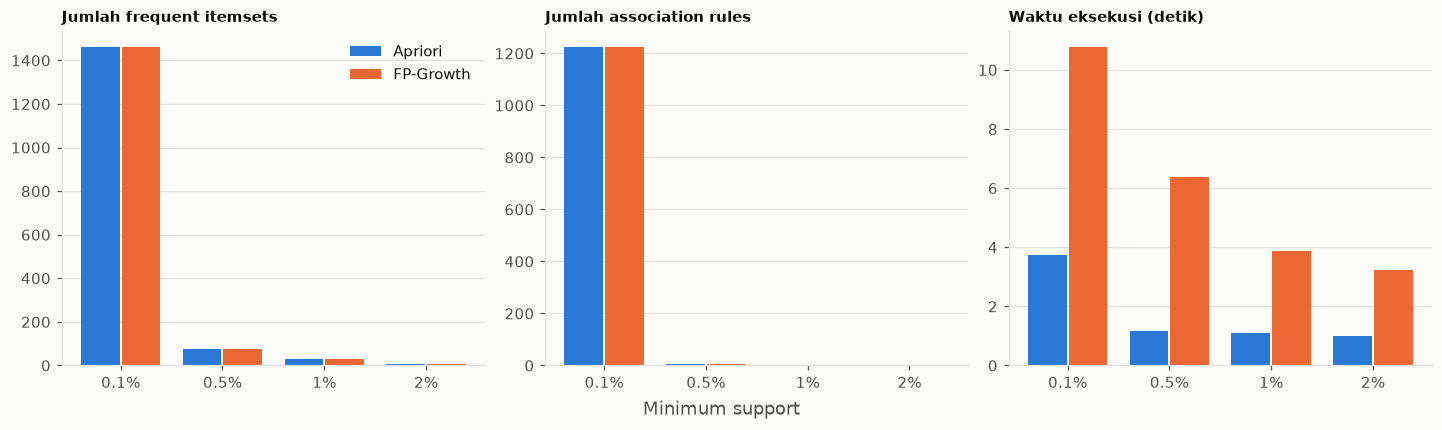

In [4]:
fig , axes = plt.subplots(1 , 3 , figsize = (13 , 3.8) , layout = "constrained")
for (ax , column , title) in (zip(axes , ["n_frequent_itemsets" , "n_rules" , "time_s"] , ["Jumlah frequent itemsets" , "Jumlah association rules" , "Waktu eksekusi (detik)"])) :
    table = perf.pivot(index = "min_support_pct" , columns = "algorithm" , values = column).reindex(SUPPORT_LEVELS)
    for (i , name) in (enumerate(COLORS)) :
        ax.bar([x + (i - 0.5) * 0.4 for (x) in range (len(table))] , table[name] , width = 0.38 , color = COLORS[name] , label = name)
    ax.set_xticks(range (len(table)) , [f"{value}%" for (value) in (table.index)])
    ax.set_title(title , fontsize = 10)
    ax.grid(axis = "x" , visible = False)
axes[0].legend()
fig.supxlabel("Minimum support" , color = TEXT_MUTED)
save(fig , "06_performance_comparison")
plt.show()

## 3. Kesamaan Hasil

- `itemsets_identical = True` berarti itemset dan support count sama persis.
- `rules_identical = True` berarti rules beserta support, confidence, dan lift sama persis.

In [5]:
display(agreement)

,min_support_pct,itemsets_identical,rules_identical
0,0.1,True,True
1,0.5,True,True
2,1,True,True
3,2,True,True


## 4. Jawaban Pertanyaan Task 6

- **Pengaruh minimum support terhadap performa**:
  - Semakin rendah support, semakin banyak itemset dan rules (1.462 itemset dan 1.225 rules pada 0,1%, sedangkan 2% hanya 5 itemset dan 0 rules).
  - Waktu Apriori naik dari 1,01 s (2%) menjadi 3,72 s (0,1%), sedangkan FP-Growth naik dari 3,25 s menjadi 10,78 s.
  - Pada Apriori, venue yang lolos dan kandidat yang diuji bertambah (582 venue frequent dan 169.071 kandidat pasangan pada 0,1%). Pada FP-Growth, ukuran FP-tree dan jumlah conditional FP-tree bertambah.
  - Sehingga kedua algoritma paling lambat pada support 0,1%, yaitu sekitar 3,7 kali (Apriori) dan 3,3 kali (FP-Growth) lebih lambat daripada support 2%.
- **Apakah frequent itemsets sama?**
  - Iya, frequent itemsets, support count, dan rules sama pada semua minimum support, terbukti dari tabel Kesamaan Hasil.
  - Hal ini sesuai teori karena kedua algoritma bersifat *complete* dan memakai ambang yang sama.
- **Algoritma yang lebih sesuai untuk DBLP**:
  - Apriori kelompok lebih cepat pada semua minimum support, yaitu 2,9 kali (0,1%), 5,4 kali (0,5%), 3,6 kali (1%), dan 3,2 kali (2%) lebih cepat daripada FP-Growth.
  - Hal ini terjadi karena data DBLP sangat *sparse*: 58% transaksi hanya memiliki satu venue dan pola terpanjang hanya 6 venue. Kandidat Apriori tidak meledak, dan penghitungan pasangan cepat karena memakai matriks sparse NumPy/SciPy.
  - FP-Growth ditulis dengan Python murni dan harus membangun FP-tree dari 1,8 juta transaksi, sehingga overhead-nya lebih besar walaupun tidak membangkitkan kandidat.
  - Sehingga dapat disimpulkan bahwa untuk dataset DBLP dengan minimum support 0,1%–2%, Apriori kelompok lebih sesuai. Secara teori, FP-Growth baru lebih unggul jika support diturunkan jauh atau pola menjadi lebih panjang, karena jumlah kandidat Apriori akan meningkat tajam.